In [2]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist23mona23/spec_df.pkl')
nist_spectra_df

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,res,ace,nce,prec_mz,peaks,ri,group_id
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,4,NaN,44.0,132.0768,"[(53.0135, 2.4), (55.018, 55.2), (55.0292, 4.2...",NaN,0
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,4,NaN,54.0,132.0768,"[(53.0135, 5.6), (55.018, 82.6), (55.0293, 7.1...",NaN,0
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,4,NaN,65.0,132.0768,"[(51.0231, 8.7), (53.0136, 12.1), (55.018, 107...",NaN,0
3,3,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461658,N2,4,NaN,76.0,132.0768,"[(51.0231, 23.8), (53.0136, 30.9), (55.018, 12...",NaN,0
4,4,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461659,N2,4,NaN,88.0,132.0768,"[(51.0231, 76.4), (53.0136, 110.0), (55.018, 1...",NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1899592,1899587,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000010,NaN,4,NaN,50.0,506.3318,"[(56.0502, 37.264882), (57.0706, 38.137391), (...",NaN,370611
1899593,1899588,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000009,NaN,4,NaN,35.0,506.3318,"[(56.0502, 8.156297), (57.0706, 10.644887), (6...",NaN,370611
1899594,1899589,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000008,NaN,4,NaN,30.0,506.3318,"[(56.0502, 4.315988), (57.0706, 5.02635), (60....",NaN,370611
1899595,1899590,12331,[M+H]+,FT,HCD,MS2,P,mona23,AC000007,NaN,4,NaN,20.0,506.3318,"[(276.2686, 3.505299), (294.2792, 24.68621), (...",NaN,370611


In [3]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist23_hr1', 'nist23_hr2'])]
nist_spectra_df.shape

(1754467, 17)

In [4]:
nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)

/tmp/ipykernel_31910/1389500530.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)


In [5]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = nist_spectra_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 27022

Top adduct types:

prec_type
[M+H]+                          529051
[M-H]-                          182447
[M+H-H2O]+                      121749
[2M+H]+                          62232
[M+Na]+                          61734
                                 ...  
[M-H-CO2-C3H6O2]-                    1
[M-H-C2H2O2-C3H2O3]-                 1
[M+H-C6H12O6-C16H24O4-C4H8]+         1
[M-H-C2H2O2-C3H2O3-CH4]-             1
[M+H-H2O-C2H2N2]+                    1
Name: count, Length: 27022, dtype: int64


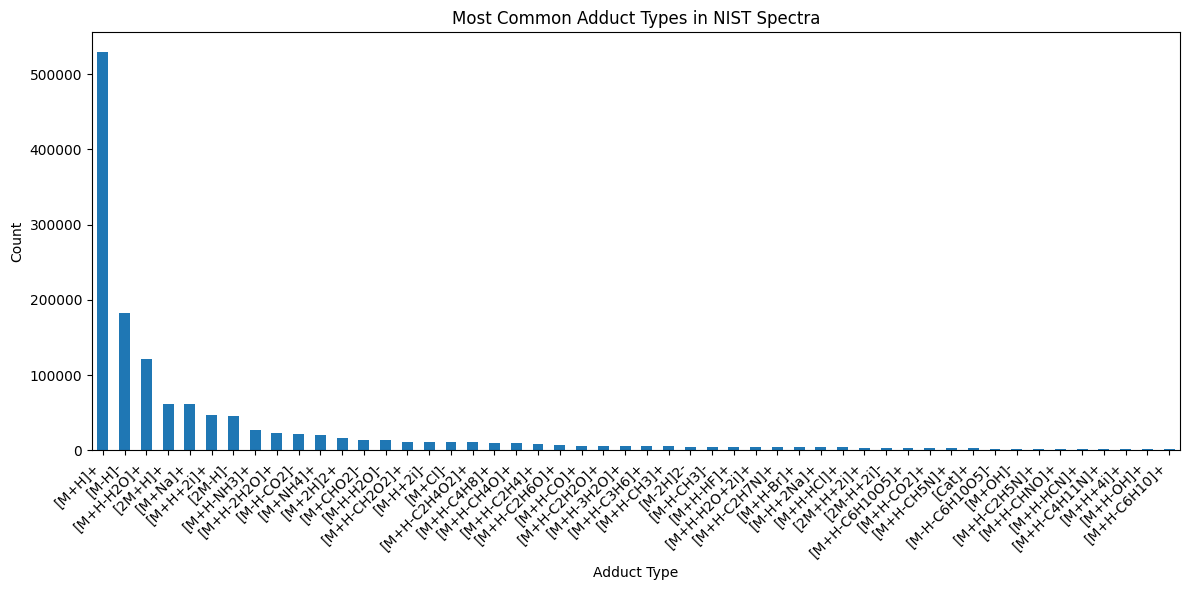

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

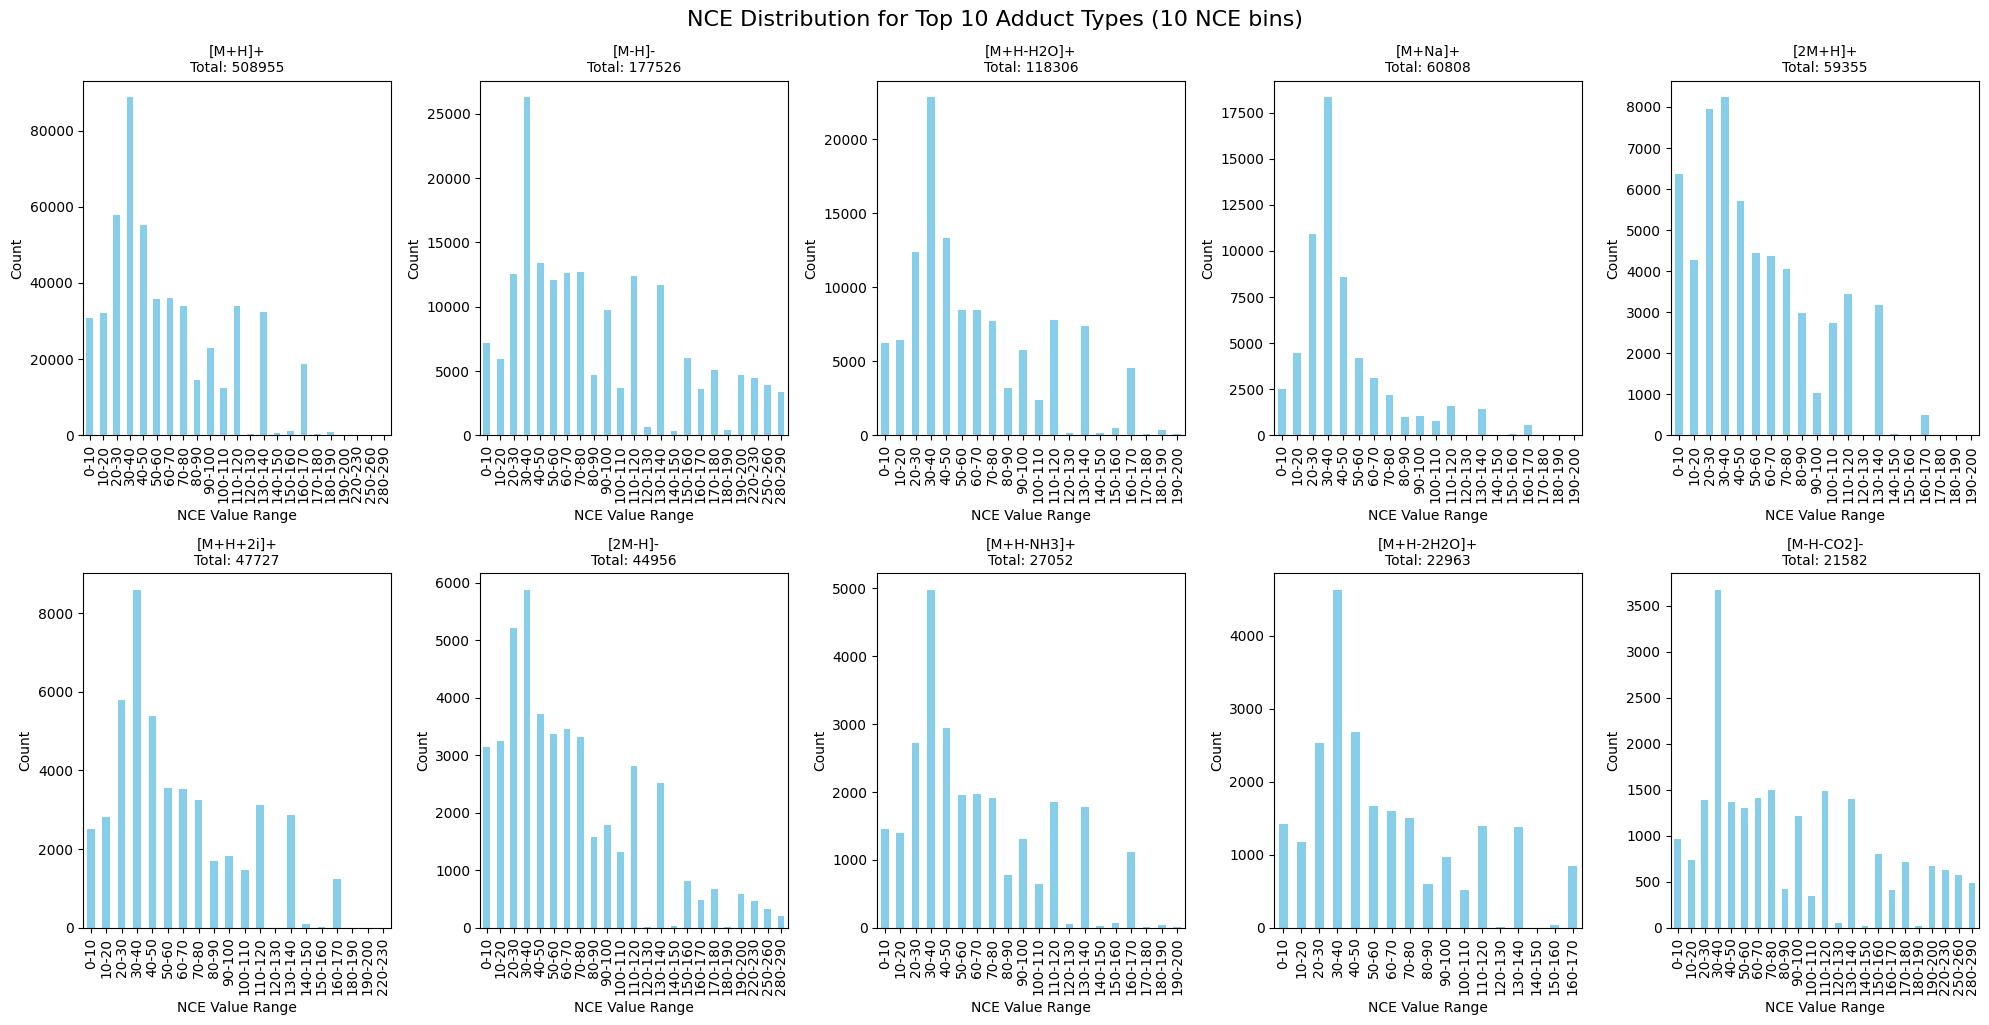

In [7]:
import numpy as np

prec_type_nce_counts = nist_spectra_df.groupby(['prec_type', 'nce']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_nce_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define NCE bins
nce_bin_size = 10
bins = np.arange(0, 325, nce_bin_size)
bin_labels = [f"{b}-{b+nce_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_nce_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('NCE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'NCE Distribution for Top 10 Adduct Types ({nce_bin_size} NCE bins)', fontsize=16, y=1.02)
plt.show()

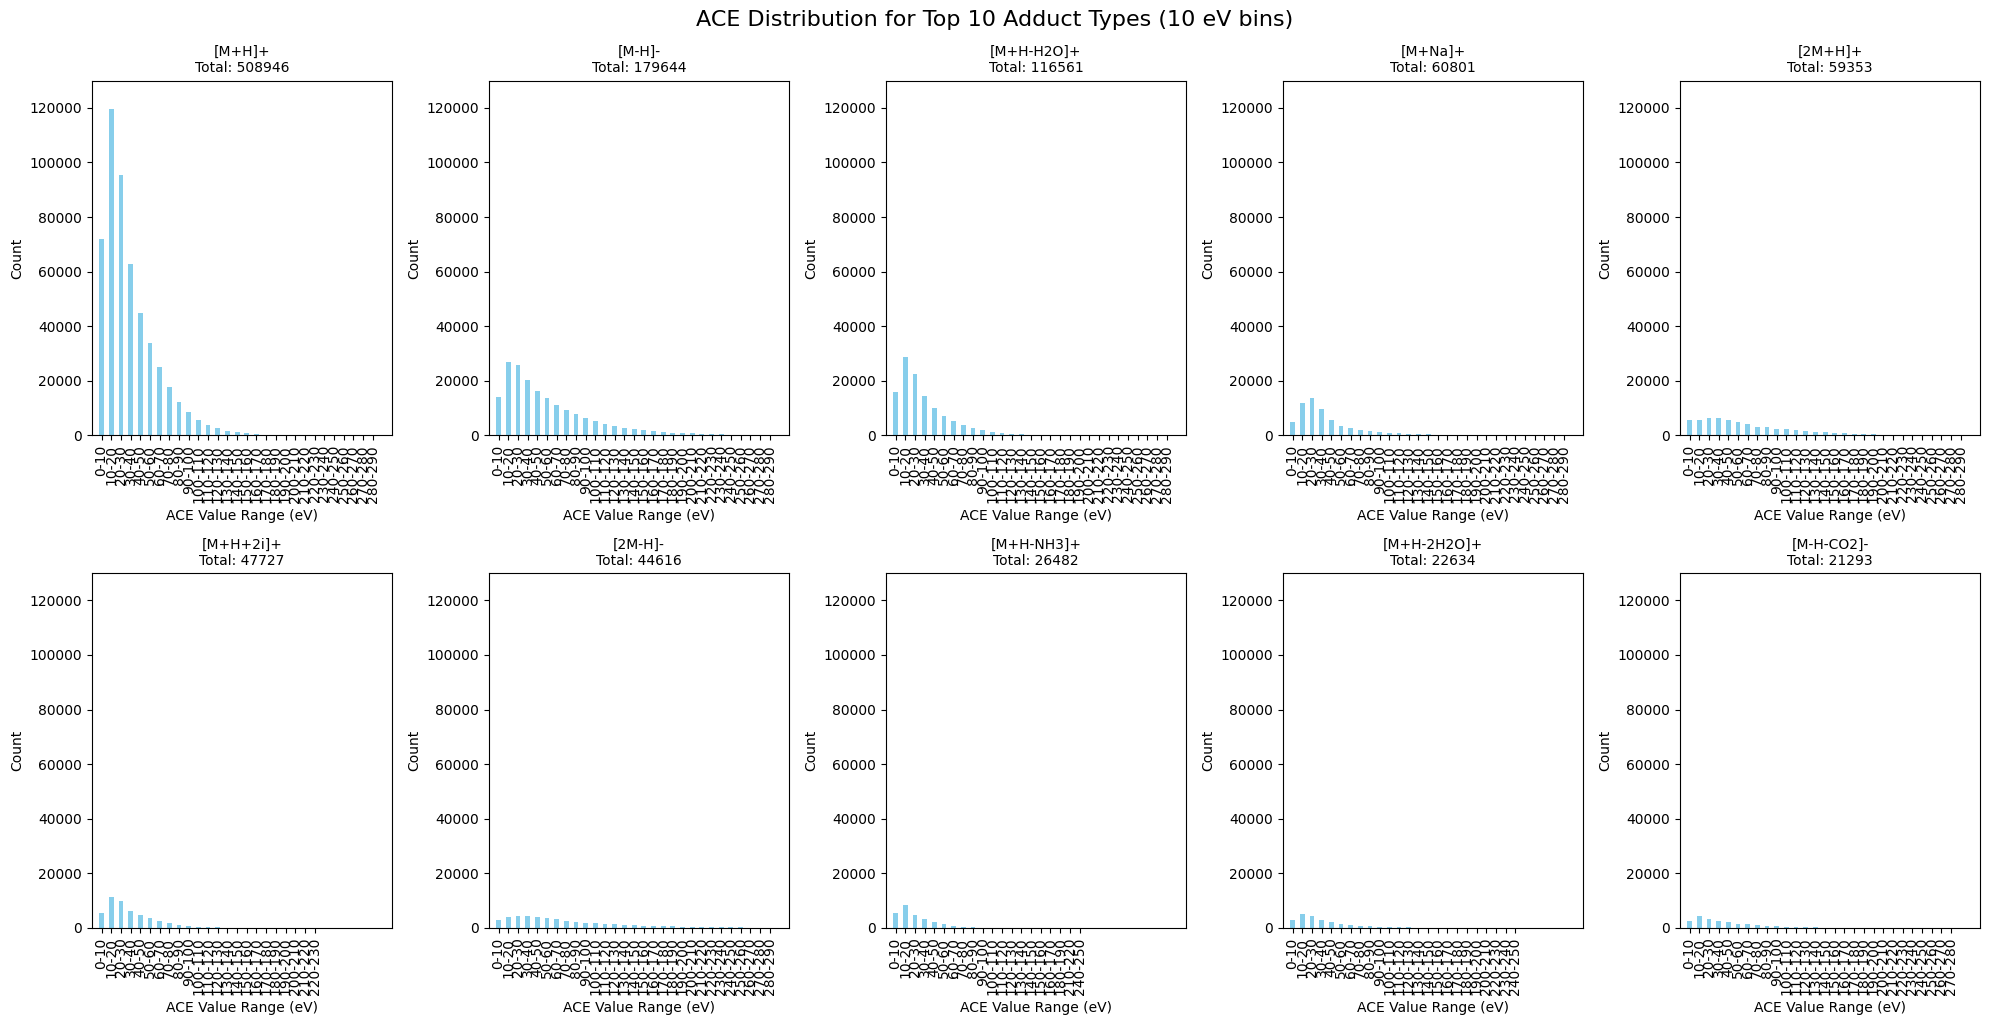

In [19]:
import numpy as np

prec_type_ace_counts = nist_spectra_df.groupby(['prec_type', 'ace']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_ace_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define ACE bins
ace_bin_size = 10
bins = np.arange(0, 300, ace_bin_size)
bin_labels = [f"{b}-{b+ace_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    ace_data = prec_type_ace_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in ace_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += ace_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('ACE Value Range (eV)')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 130_000)
    ax.set_xlim(-1, 30)
    
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'ACE Distribution for Top 10 Adduct Types ({ace_bin_size} eV bins)', fontsize=16, y=1.02)
plt.show()

In [10]:
nist_mol_df = pd.read_pickle('../../data/proc/nist23mona23/mol_df.pkl')
nist_mol_df.head()

,smiles,mol_id,mol,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,<rdkit.Chem.rdchem.Mol object at 0x7fbf38841990>,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC(Br)(Br)c1cnc2ccccc2n1,1,<rdkit.Chem.rdchem.Mol object at 0x7fbf38841a30>,VCCOPRMZNNMFLI,c1ccc2nccnc2c1,C9H5Br3N2,"InChI=1S/C9H5Br3N2/c10-9(11,12)8-5-13-6-3-1-2-...",380.865,377.800284,14,15,0,True,0
2,BrC1=CCCN(Cc2ccccc2)C1,2,<rdkit.Chem.rdchem.Mol object at 0x7fbf38841ad0>,OFHMQSKRHZDSQE,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-7-4-8-14(10-12)9-11-...,252.155,251.030962,14,15,0,True,0
3,BrC1=CCN(Cc2ccccc2)CC1,3,<rdkit.Chem.rdchem.Mol object at 0x7fbf38201b20>,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
4,BrC1CCCCCC(Br)C12OCCO2,4,<rdkit.Chem.rdchem.Mol object at 0x7fbf38841bc0>,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0


In [15]:
nist_mol_df.iloc[0]

smiles          *C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...
mol_id                                                          0
mol              <rdkit.Chem.rdchem.Mol object at 0x7fbf38841990>
inchikey_s                                                       
scaffold        O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...
formula                                                C47H75*O19
inchi                                                            
mw                                                        944.098
exact_mw                                               943.490255
num_atoms                                                      67
num_bonds                                                      74
charge                                                          0
single_mol                                                   True
num_radicals                                                    0
Name: 0, dtype: object

In [12]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')

nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
3,3,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461658,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0
4,4,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461659,N2,...,,C4H9N3O2,"InChI=1S/C4H9N3O2/c1-2(3(8)9)7-4(5)6/h2H,1H3,(...",131.135,131.069477,9,8,0,True,0


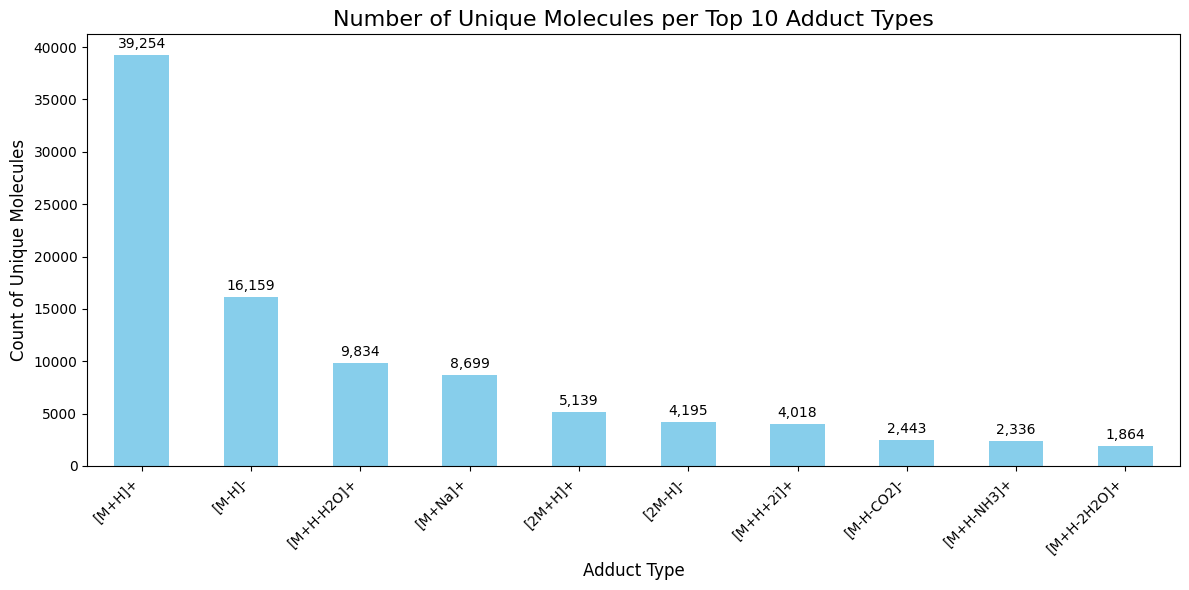

Number of unique molecules per adduct type:
prec_type
[M+H]+         39254
[M-H]-         16159
[M+H-H2O]+      9834
[M+Na]+         8699
[2M+H]+         5139
[2M-H]-         4195
[M+H+2i]+       4018
[M-H-CO2]-      2443
[M+H-NH3]+      2336
[M+H-2H2O]+     1864
Name: mol_id, dtype: int64


In [21]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)